In [3]:
print("Hi Vardhan, Welcome to IPL Data Analysis Project")

Hi Vardhan, Welcome to IPL Data Analysis Project


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
matches = pd.read_csv("data/matches.csv")

deliveries = pd.read_csv("data/deliveries.csv")

print("IPL datasets loaded successfully!")

IPL datasets loaded successfully!


In [8]:
matches.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


In [9]:
deliveries.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [10]:
print("Matches:", matches.shape)

print("Deliveries:", deliveries.shape)

Matches: (1095, 20)
Deliveries: (260920, 17)


In [11]:
matches.columns

Index(['id', 'season', 'city', 'date', 'match_type', 'player_of_match',
       'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'winner',
       'result', 'result_margin', 'target_runs', 'target_overs', 'super_over',
       'method', 'umpire1', 'umpire2'],
      dtype='str')

In [12]:
team_wins = matches['winner'].value_counts()

print(team_wins)

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    116
Rajasthan Royals               112
Kings XI Punjab                 88
Sunrisers Hyderabad             88
Delhi Daredevils                67
Delhi Capitals                  48
Deccan Chargers                 29
Gujarat Titans                  28
Punjab Kings                    24
Lucknow Super Giants            24
Gujarat Lions                   13
Pune Warriors                   12
Rising Pune Supergiant          10
Royal Challengers Bengaluru      7
Kochi Tuskers Kerala             6
Rising Pune Supergiants          5
Name: count, dtype: int64


In [13]:
team_wins.head(5)

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    116
Rajasthan Royals               112
Name: count, dtype: int64

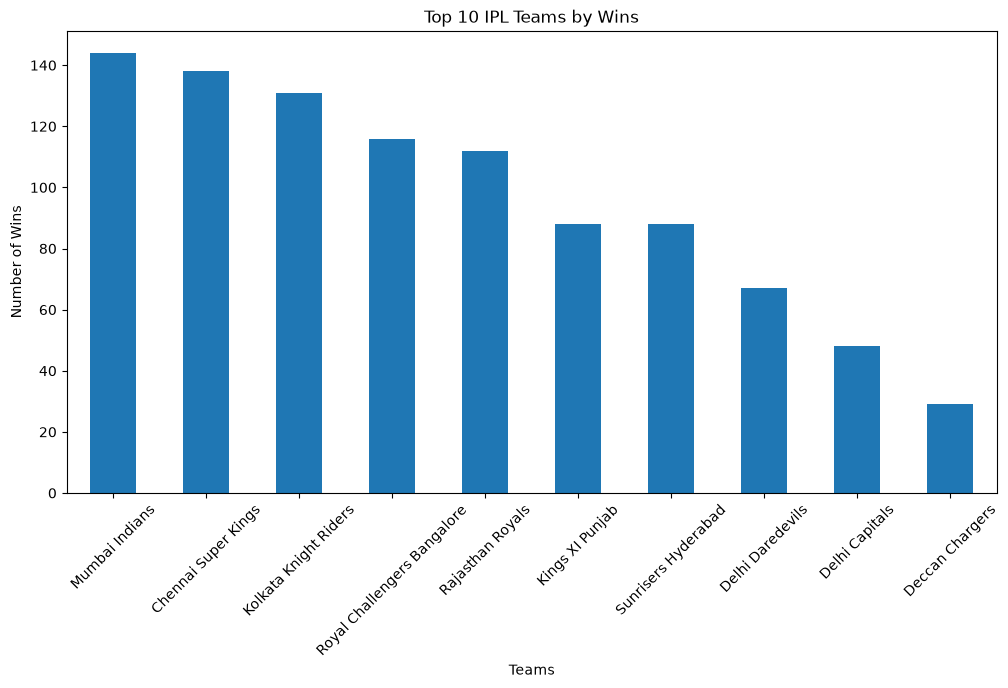

In [14]:
plt.figure(figsize=(12, 6))

team_wins.head(10).plot(kind='bar')

plt.title("Top 10 IPL Teams by Wins")

plt.xlabel("Teams")

plt.ylabel("Number of Wins")

plt.xticks(rotation=45)

plt.show()

In [15]:
batsman_runs = deliveries.groupby('batter')['batsman_runs'].sum()

print(batsman_runs.sort_values(ascending=False).head(10))

batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
Name: batsman_runs, dtype: int64


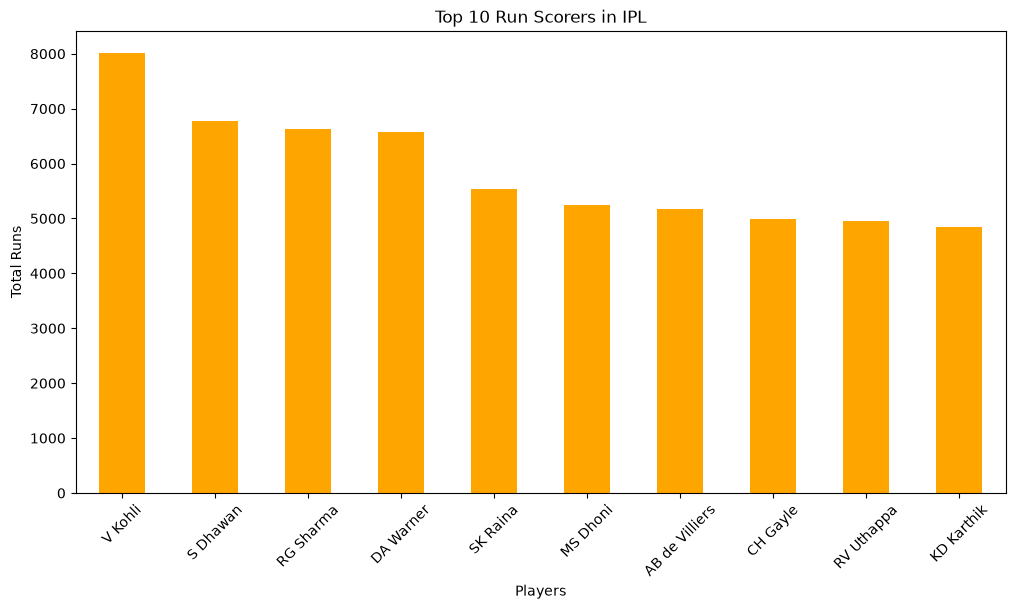

In [16]:
top_batsmen = batsman_runs.sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))

top_batsmen.plot(kind='bar', color='orange')

plt.title("Top 10 Run Scorers in IPL")

plt.xlabel("Players")

plt.ylabel("Total Runs")

plt.xticks(rotation=45)

plt.show()

In [17]:
top_player = batsman_runs.idxmax()

highest_runs = batsman_runs.max()

print("Top Batsman:", top_player)

print("Total Runs:", highest_runs)

Top Batsman: V Kohli
Total Runs: 8014


In [18]:
# Remove rows without a dismissal
wickets = deliveries[deliveries['dismissal_kind'].notna()]

# Exclude dismissals not credited to the bowler
wickets = wickets[
    ~wickets['dismissal_kind'].isin(
        ['run out', 'retired hurt', 'obstructing the field', 'retired out']
    )
]

# Count wickets for each bowler
bowler_wickets = wickets.groupby('bowler').size()

# Display top 10 bowlers
bowler_wickets = bowler_wickets.sort_values(ascending=False)

print(bowler_wickets.head(10))

bowler
YS Chahal     205
PP Chawla     192
DJ Bravo      183
B Kumar       181
SP Narine     180
R Ashwin      180
A Mishra      174
SL Malinga    170
JJ Bumrah     168
RA Jadeja     160
dtype: int64


In [19]:
top_bowler = bowler_wickets.idxmax()

highest_wickets = bowler_wickets.max()

print("Top Bowler:", top_bowler)

print("Total Wickets:", highest_wickets)

Top Bowler: YS Chahal
Total Wickets: 205


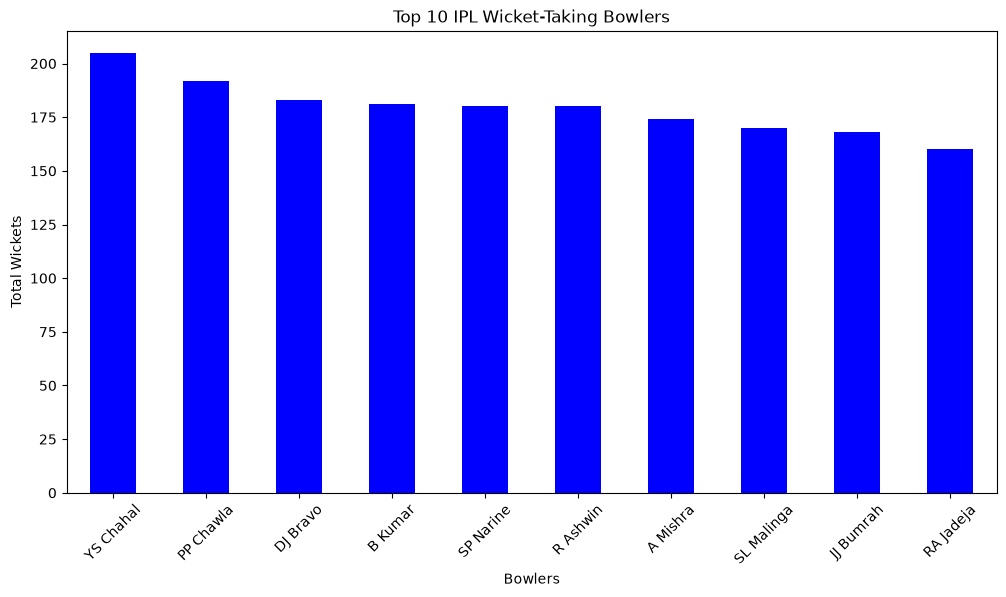

In [20]:
top_10_bowlers = bowler_wickets.head(10)

plt.figure(figsize=(12, 6))

top_10_bowlers.plot(kind='bar', color='blue')

plt.title("Top 10 IPL Wicket-Taking Bowlers")

plt.xlabel("Bowlers")

plt.ylabel("Total Wickets")

plt.xticks(rotation=45)

plt.show()